# Module Two - Data Three Ways

**Applied Computer Vision / Data Visualization (Module Two)**<br>
Student: Taher Turki<br>
October 2026

## Decoupling or outsourcing?

**Has economic growth in post-industrial nations genuinely decoupled from carbon emissions, or
have wealthy countries merely outsourced their environmental footprint by importing
emissions-intensive manufactured goods from developing nations?**

This notebook answers that with one dataset drawn three ways, on three platforms:

| # | Idiom | Platform | What it is for |
|---|---|---|---|
| 1 | Linked views: indexed time series + bubble scatter, joined by an interval brush | Altair (Vega-Lite) | where 109 countries sit between importing and exporting CO2, for any window of years |
| 2 | Connected scatterplot (phase-space trajectories) with a year scrubber | D3 v7 | the path each of six countries took through income and footprint |
| 3 | Small multiples of a diverging area chart | Seaborn / Matplotlib | the gap between what a country emits and what it consumes, in tonnes |

It remixes Hannah Ritchie's Our World in Data article *Many countries have decoupled economic
growth from CO2 emissions, even if we take offshored production into account* (1 December 2021,
https://ourworldindata.org/co2-gdp-decoupling) with the same publisher's CO2 dataset, updated to
2022.

The code lives in `../scripts/` and `../web/`; each cell imports it and calls it, so the notebook
and the standalone scripts cannot drift apart. Visualization 2 (the D3 chart) was built with AI coding
assistance; Visualizations 1 and 3 and the written analysis were completed
independently, as the report states for each one.

## Setup

Inline figures and `../scripts` on the import path.

In [1]:
%matplotlib inline
import os, sys, platform
sys.path.insert(0, os.path.abspath(os.path.join("..", "scripts")))

import altair as alt
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import HTML, Image, display

import common

plt.rcParams["figure.dpi"] = 100        # inline preview size; the saved PNGs keep their own dpi
pd.set_option("display.float_format", "{:,.2f}".format)

print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| altair", alt.__version__, "| matplotlib", matplotlib.__version__,
      "| seaborn", sns.__version__)

python 3.12.14 | numpy 2.5.3 | pandas 3.0.6 | altair 6.3.0 | matplotlib 3.11.2 | seaborn 0.13.2


## The story being remixed

Ritchie's article makes its case with two chart forms. The first is an interactive line chart,
one country per panel, of the percent change since 1990 in GDP per capita and in CO2 per capita on
both accounts. The second is a static grid of 30 countries, each drawn as two arrows for 2005-20.
They are reproduced unaltered under OWID's CC BY licence. The line chart is OWID's own export as
served on 4 October 2026, so it runs past the 2021 article; the middle image is the same chart
after China is added, which is where an indexed percent axis stops working.

MODULE TWO - THE ORIGINAL STORY'S CHARTS

1. Originals re-saved as PNG, no resampling
-------------------------------------------
   check: original_owid_line_chart_gbr.png is present in inputs/ ... PASS
   inputs\original_owid_line_chart_gbr.png  1700 x 1200 px  ->  screenshots\00a_original_owid_line_chart.png
   check: 00a_original_owid_line_chart.png has the original's pixel dimensions (1700 x 1200) ... PASS
   result: original_line_chart_width_px = 1700
   result: original_line_chart_height_px = 1200
   check: original_owid_line_chart_gbr_chn.png is present in inputs/ ... PASS
   inputs\original_owid_line_chart_gbr_chn.png  1700 x 1200 px  ->  screenshots\00b_original_owid_two_countries.png
   check: 00b_original_owid_two_countries.png has the original's pixel dimensions (1700 x 1200) ... PASS
   result: original_two_countries_width_px = 1700
   result: original_two_countries_height_px = 1200
   check: original_owid_arrow_grid.png is present in inputs/ ... PASS


   inputs\original_owid_arrow_grid.png  2614 x 2736 px  ->  screenshots\00c_original_owid_arrow_grid.png
   check: 00c_original_owid_arrow_grid.png has the original's pixel dimensions (2614 x 2736) ... PASS
   result: original_arrow_grid_width_px = 2614
   result: original_arrow_grid_height_px = 2736

2. The data behind the original line chart (United Kingdom)
-----------------------------------------------------------
   check: original_owid_line_chart_gbr.csv is present in inputs/ ... PASS
   check: the chart's production-based CO2 per person is this project's series, 1990-2022 (worst gap 0.00000 t) ... PASS
   check: the chart's consumption-based CO2 per person is this project's series (worst gap 0.00000 t) ... PASS
   GDP per person, 1990 to 2022
      original chart, World Bank, international-$ at 2021 prices:    33,531 ->    53,980  (+61.0%)
      this project, Maddison 2023, international-$ at 2011 prices:   26,246 ->    38,358  (+46.1%)
   result: original_gbr_gdp_pc_change_pct

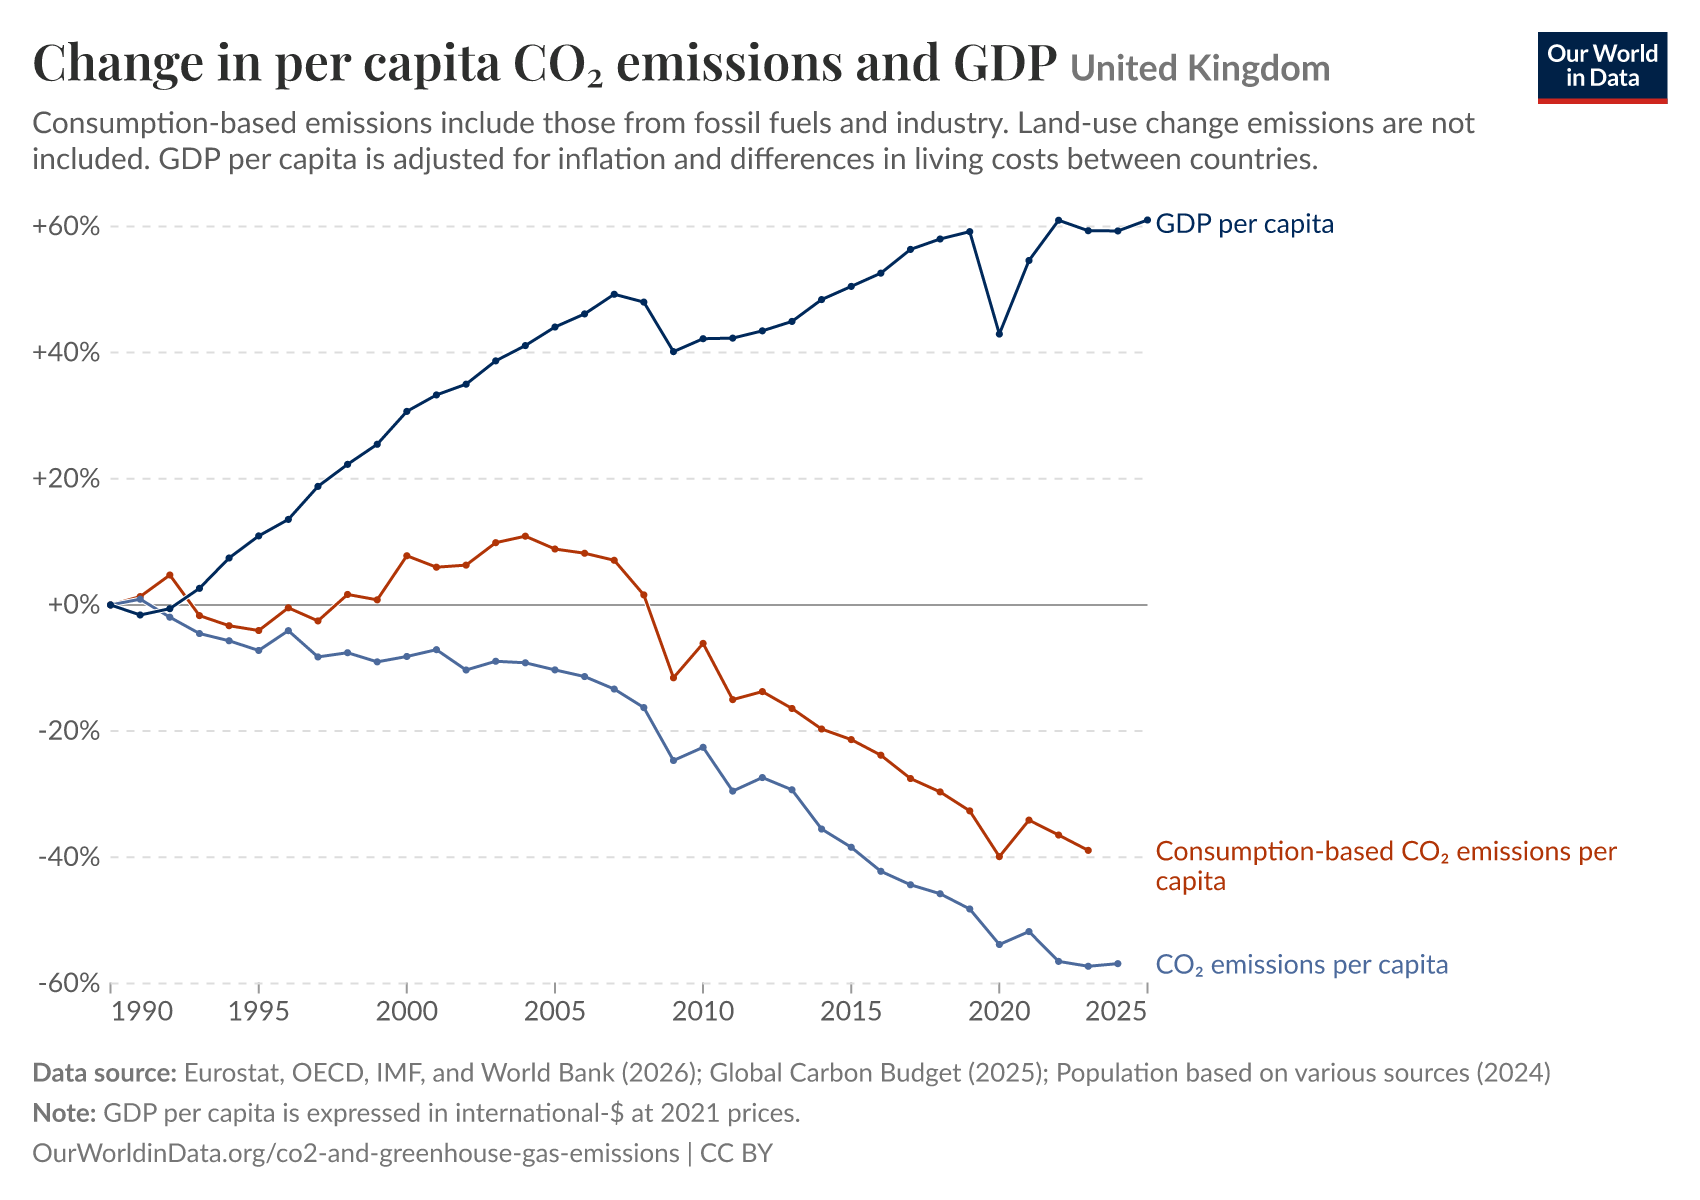

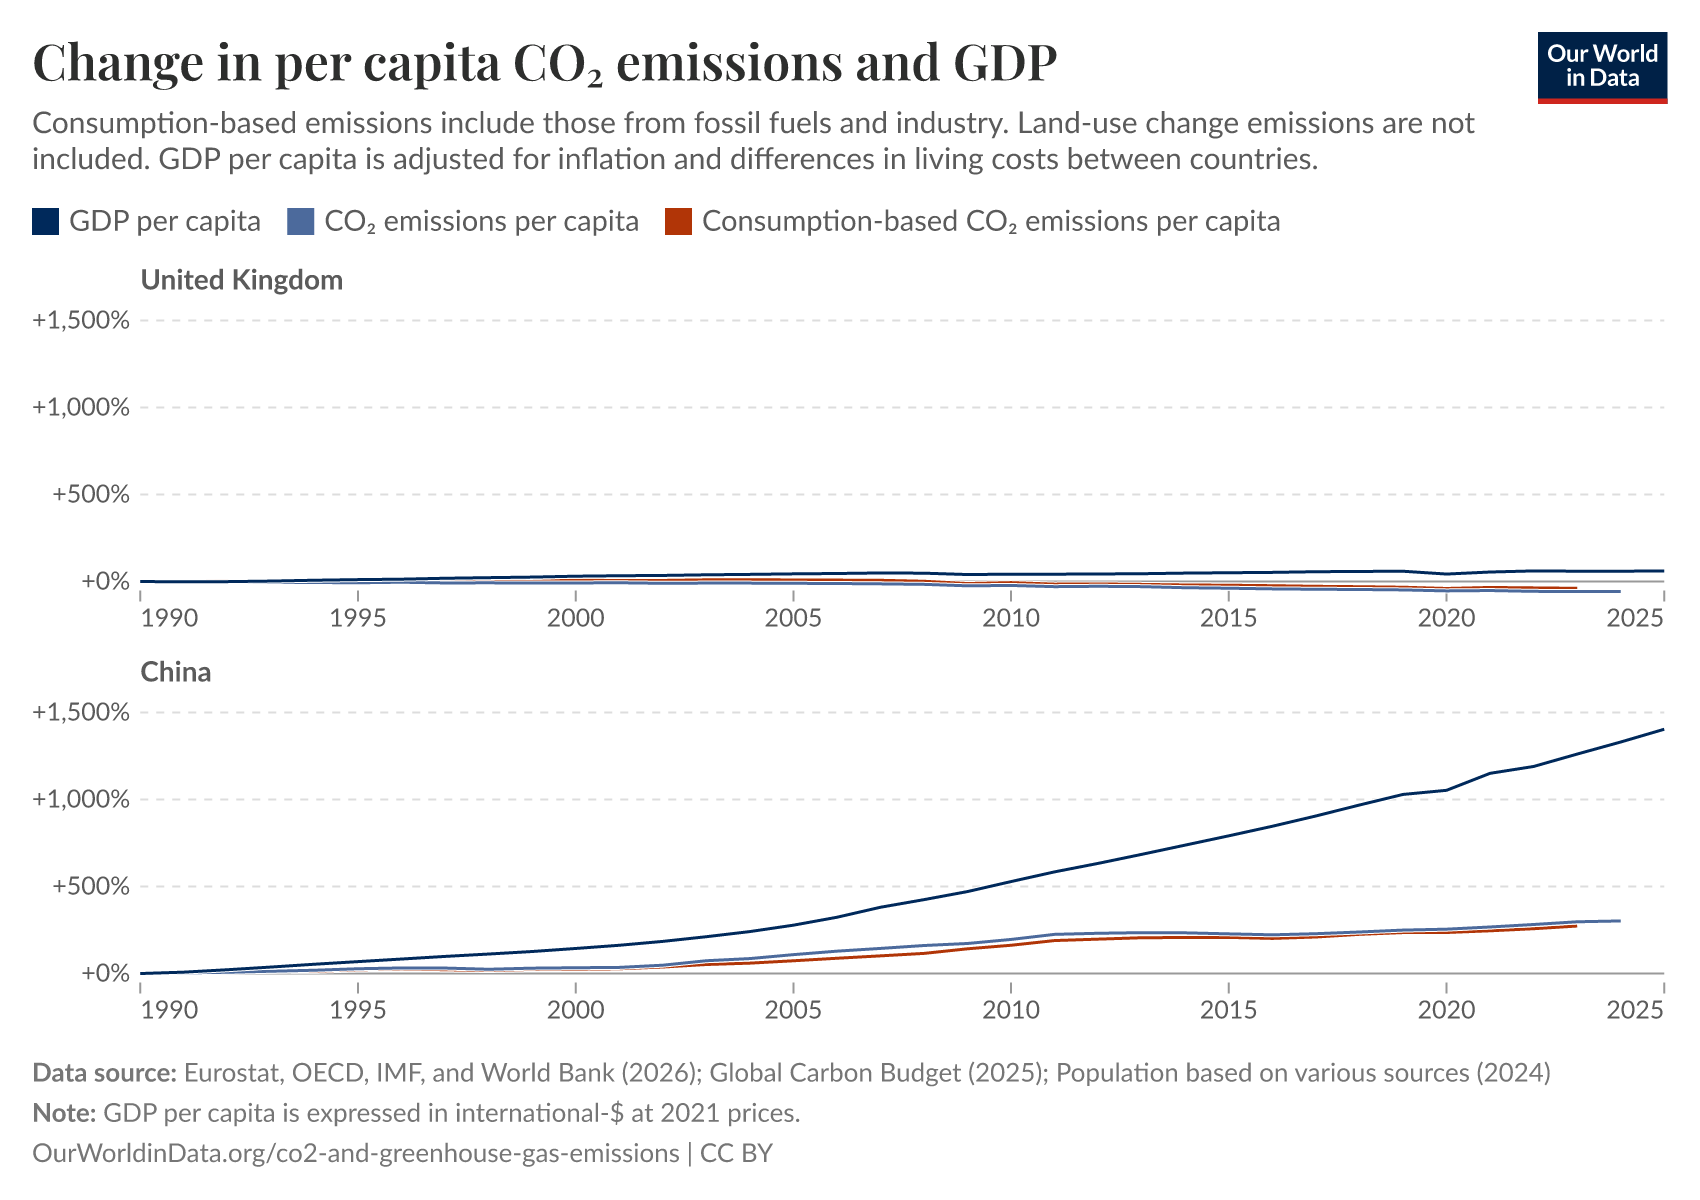

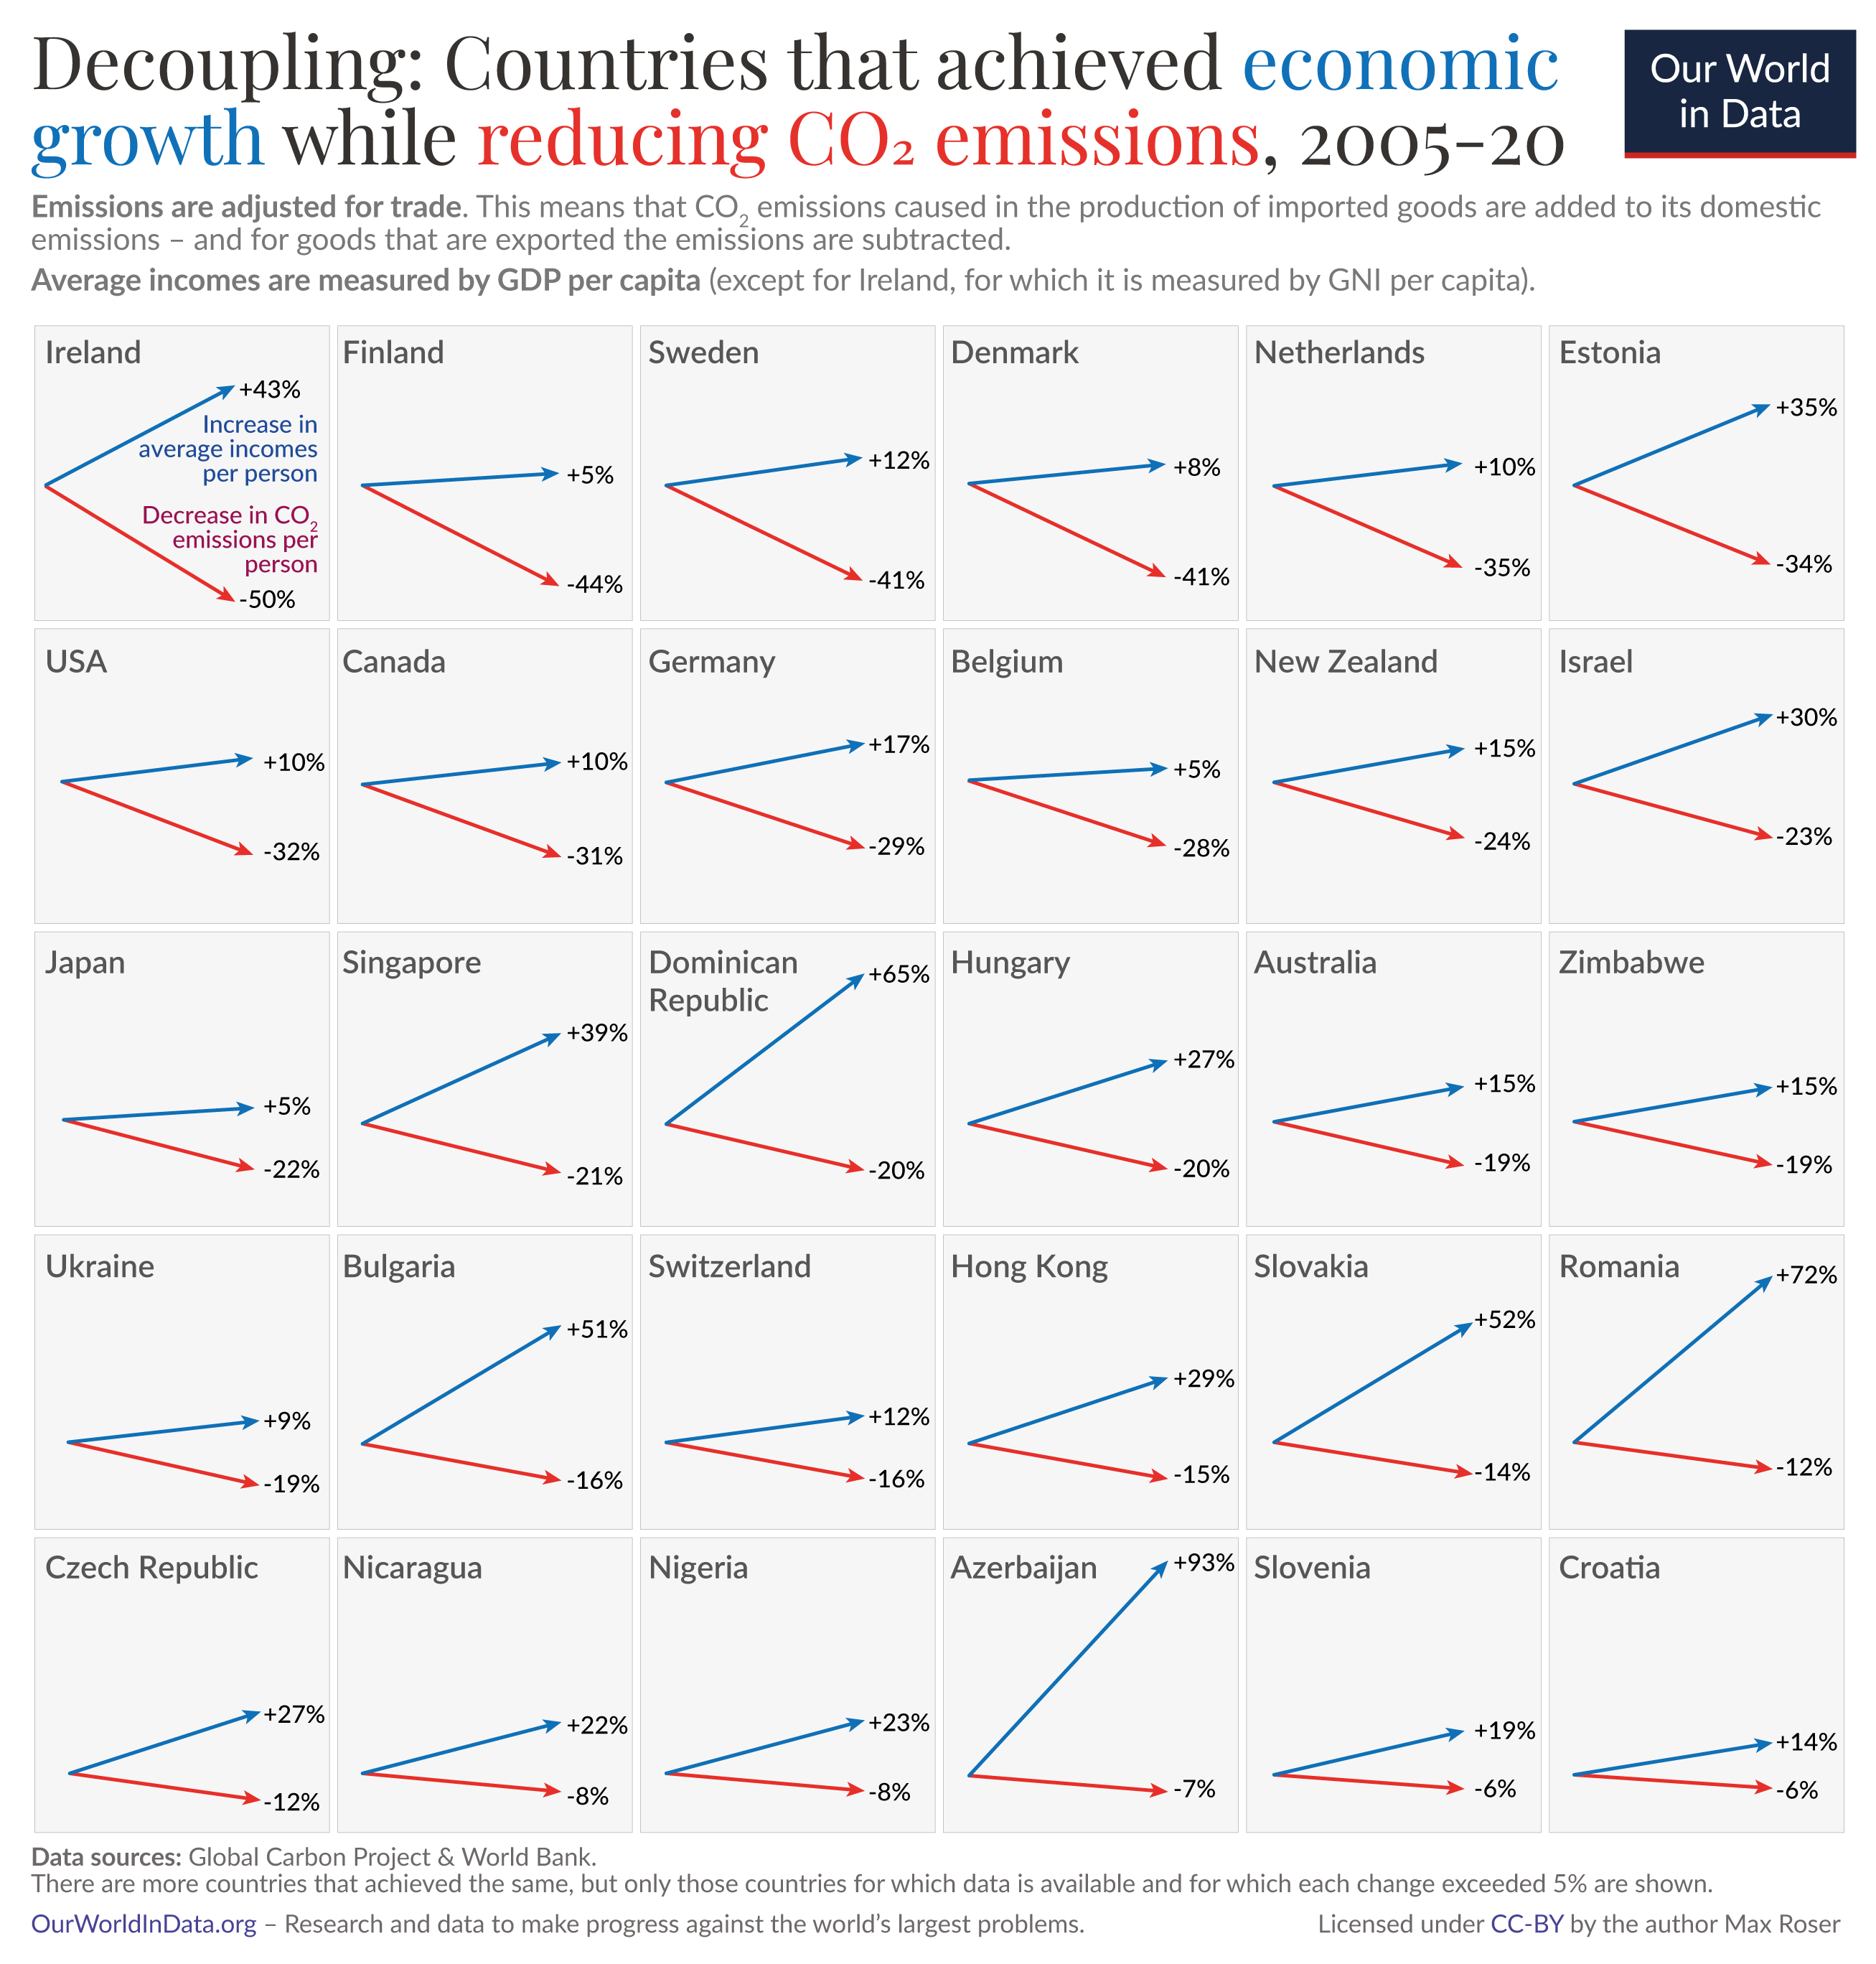

In [2]:
import original_story
originals = original_story.main()
for name in ("00a_original_owid_line_chart.png", "00b_original_owid_two_countries.png",
             "00c_original_owid_arrow_grid.png"):
    display(Image(filename=os.path.join(common.SHOTS, name), width=640))

## 1. The data

One file: the Our World in Data CO2 and Greenhouse Gas Emissions dataset, downloaded on
4 October 2026 (50,411 rows, 79 columns, 1750-2024). `prepare_data.py` keeps the 110 countries
that have GDP, population and a real CO2 estimate on both accounts in every year from 1990 to 2022,
and derives three variables:

```
gdp_per_capita     = gdp / population                             international-$, 2011 prices
net_co2_per_capita = consumption_co2_per_capita - co2_per_capita  t CO2 per person
net_co2_mt         = consumption_co2 - co2                        Mt CO2
```

A positive net balance means the country consumes more CO2 than it emits on its own territory:
it is a net importer of embodied emissions. Running the script here prints its checks on units
and identities.

In [3]:
import prepare_data
prep = prepare_data.main(show_results=False)

MODULE TWO - DATA PREPARATION
   window 1990-2022, base year 1990, focus: United States, United Kingdom, Germany, Sweden, China, India

1. Raw file
-----------
   owid-co2-data.csv: 50,411 rows, 254 entities, years 1750-2024
   gdp                          available 1820-2022
   consumption_co2_per_capita   available 1990-2024
   co2_per_capita               available 1750-2024

2. Panel
--------
   218 countries have an ISO code and at least one row in 1990-2022
   115 of them have all of population, gdp, co2, co2_per_capita, consumption_co2, consumption_co2_per_capita
   in every one of the 33 years; the rest are dropped, not interpolated
   5 of those carry placeholder consumption figures (equal to the production figure
   to within 1 part in 100,000) in 39 country-years and are dropped as incomplete:
      Belgium        1990-1998   (9 years)
      Botswana       1990-1999   (10 years)
      Luxembourg     1990-1998   (9 years)
      South Africa   1990-1999   (10 years)
      Tuni

   inputs\decoupling_panel.csv          745.9 KB   110 countries x 33 years
   inputs\decoupling_focus.csv           46.1 KB   6 countries x 33 years
   inputs\decoupling_summary.csv          4.4 KB   6 rows
   web\data\decoupling_data.js           98.7 KB   6 focus series, 104 context
   check: decoupling_focus.csv reads back as 198 rows with no missing value in the plotted columns ... PASS
   check: decoupling_data.js parses as JSON and holds the six focus series of 33 years each ... PASS

checks: 18 passed, 0 failed


The six focus countries, 1990 against 2022. GDP is per person in international-$ at 2011
prices; CO2 is in tonnes per person; the last three columns are the net balance.

In [4]:
summary = common.load_summary()
cols = {"gdp_pc_1990": "GDP 1990", "gdp_pc_2022": "GDP 2022", "gdp_pc_change_pct": "GDP %",
        "prod_pc_1990": "prod 1990", "prod_pc_2022": "prod 2022", "prod_change_pct": "prod %",
        "cons_pc_1990": "cons 1990", "cons_pc_2022": "cons 2022", "cons_change_pct": "cons %",
        "net_pc_1990": "net 1990", "net_pc_2007": "net 2007", "net_pc_2022": "net 2022"}
display(summary[list(cols)].rename(columns=cols))

,GDP 1990,GDP 2022,GDP %,prod 1990,prod 2022,prod %,cons 1990,cons 2022,cons %,net 1990,net 2007,net 2022
country,,,,,,,,,,,,
United States,"36,508.88","57,075.34",56.33,20.25,14.80,-26.92,19.94,16.30,-18.25,-0.32,1.34,1.49
United Kingdom,"26,246.27","38,358.12",46.15,10.49,4.56,-56.51,11.61,7.37,-36.48,1.12,3.34,2.81
Germany,"25,286.65","46,495.28",83.87,13.23,7.94,-39.98,15.06,9.98,-33.74,1.82,2.33,2.03
Sweden,"28,069.41","47,124.89",67.89,6.71,3.47,-48.35,13.11,6.33,-51.73,6.40,3.94,2.86
China,"2,934.44","18,921.14",544.80,2.15,8.22,281.71,2.05,7.32,257.51,-0.11,-1.14,-0.90
India,"2,024.33","7,349.57",263.06,0.67,1.99,197.24,0.67,1.64,143.41,0.01,-0.09,-0.34


## 2. Visualization 1 - linked views in Altair

Top: one country's GDP per capita and CO2 per capita on both accounts, as percent change since
1990. Bottom: 109 countries, each a bubble at its mean GDP per capita (log scale) and its mean
net balance over the years brushed in the top panel; bubble area is population and hue is the
World Bank income group.

**Try it:** drag across the years in the top panel and watch the bubbles move; drag the brush
from the 1990s to the 2010s; click outside the brush to average over all 33 years; change the
country in the dropdown under the chart.

In [5]:
import vis1_altair_linked as v1
chart = v1.build_chart()
chart

alt.VConcatChart(...)

The same view as a static image (brush on 2013-2022), for viewers that do not run
JavaScript, and the two brush positions side by side.

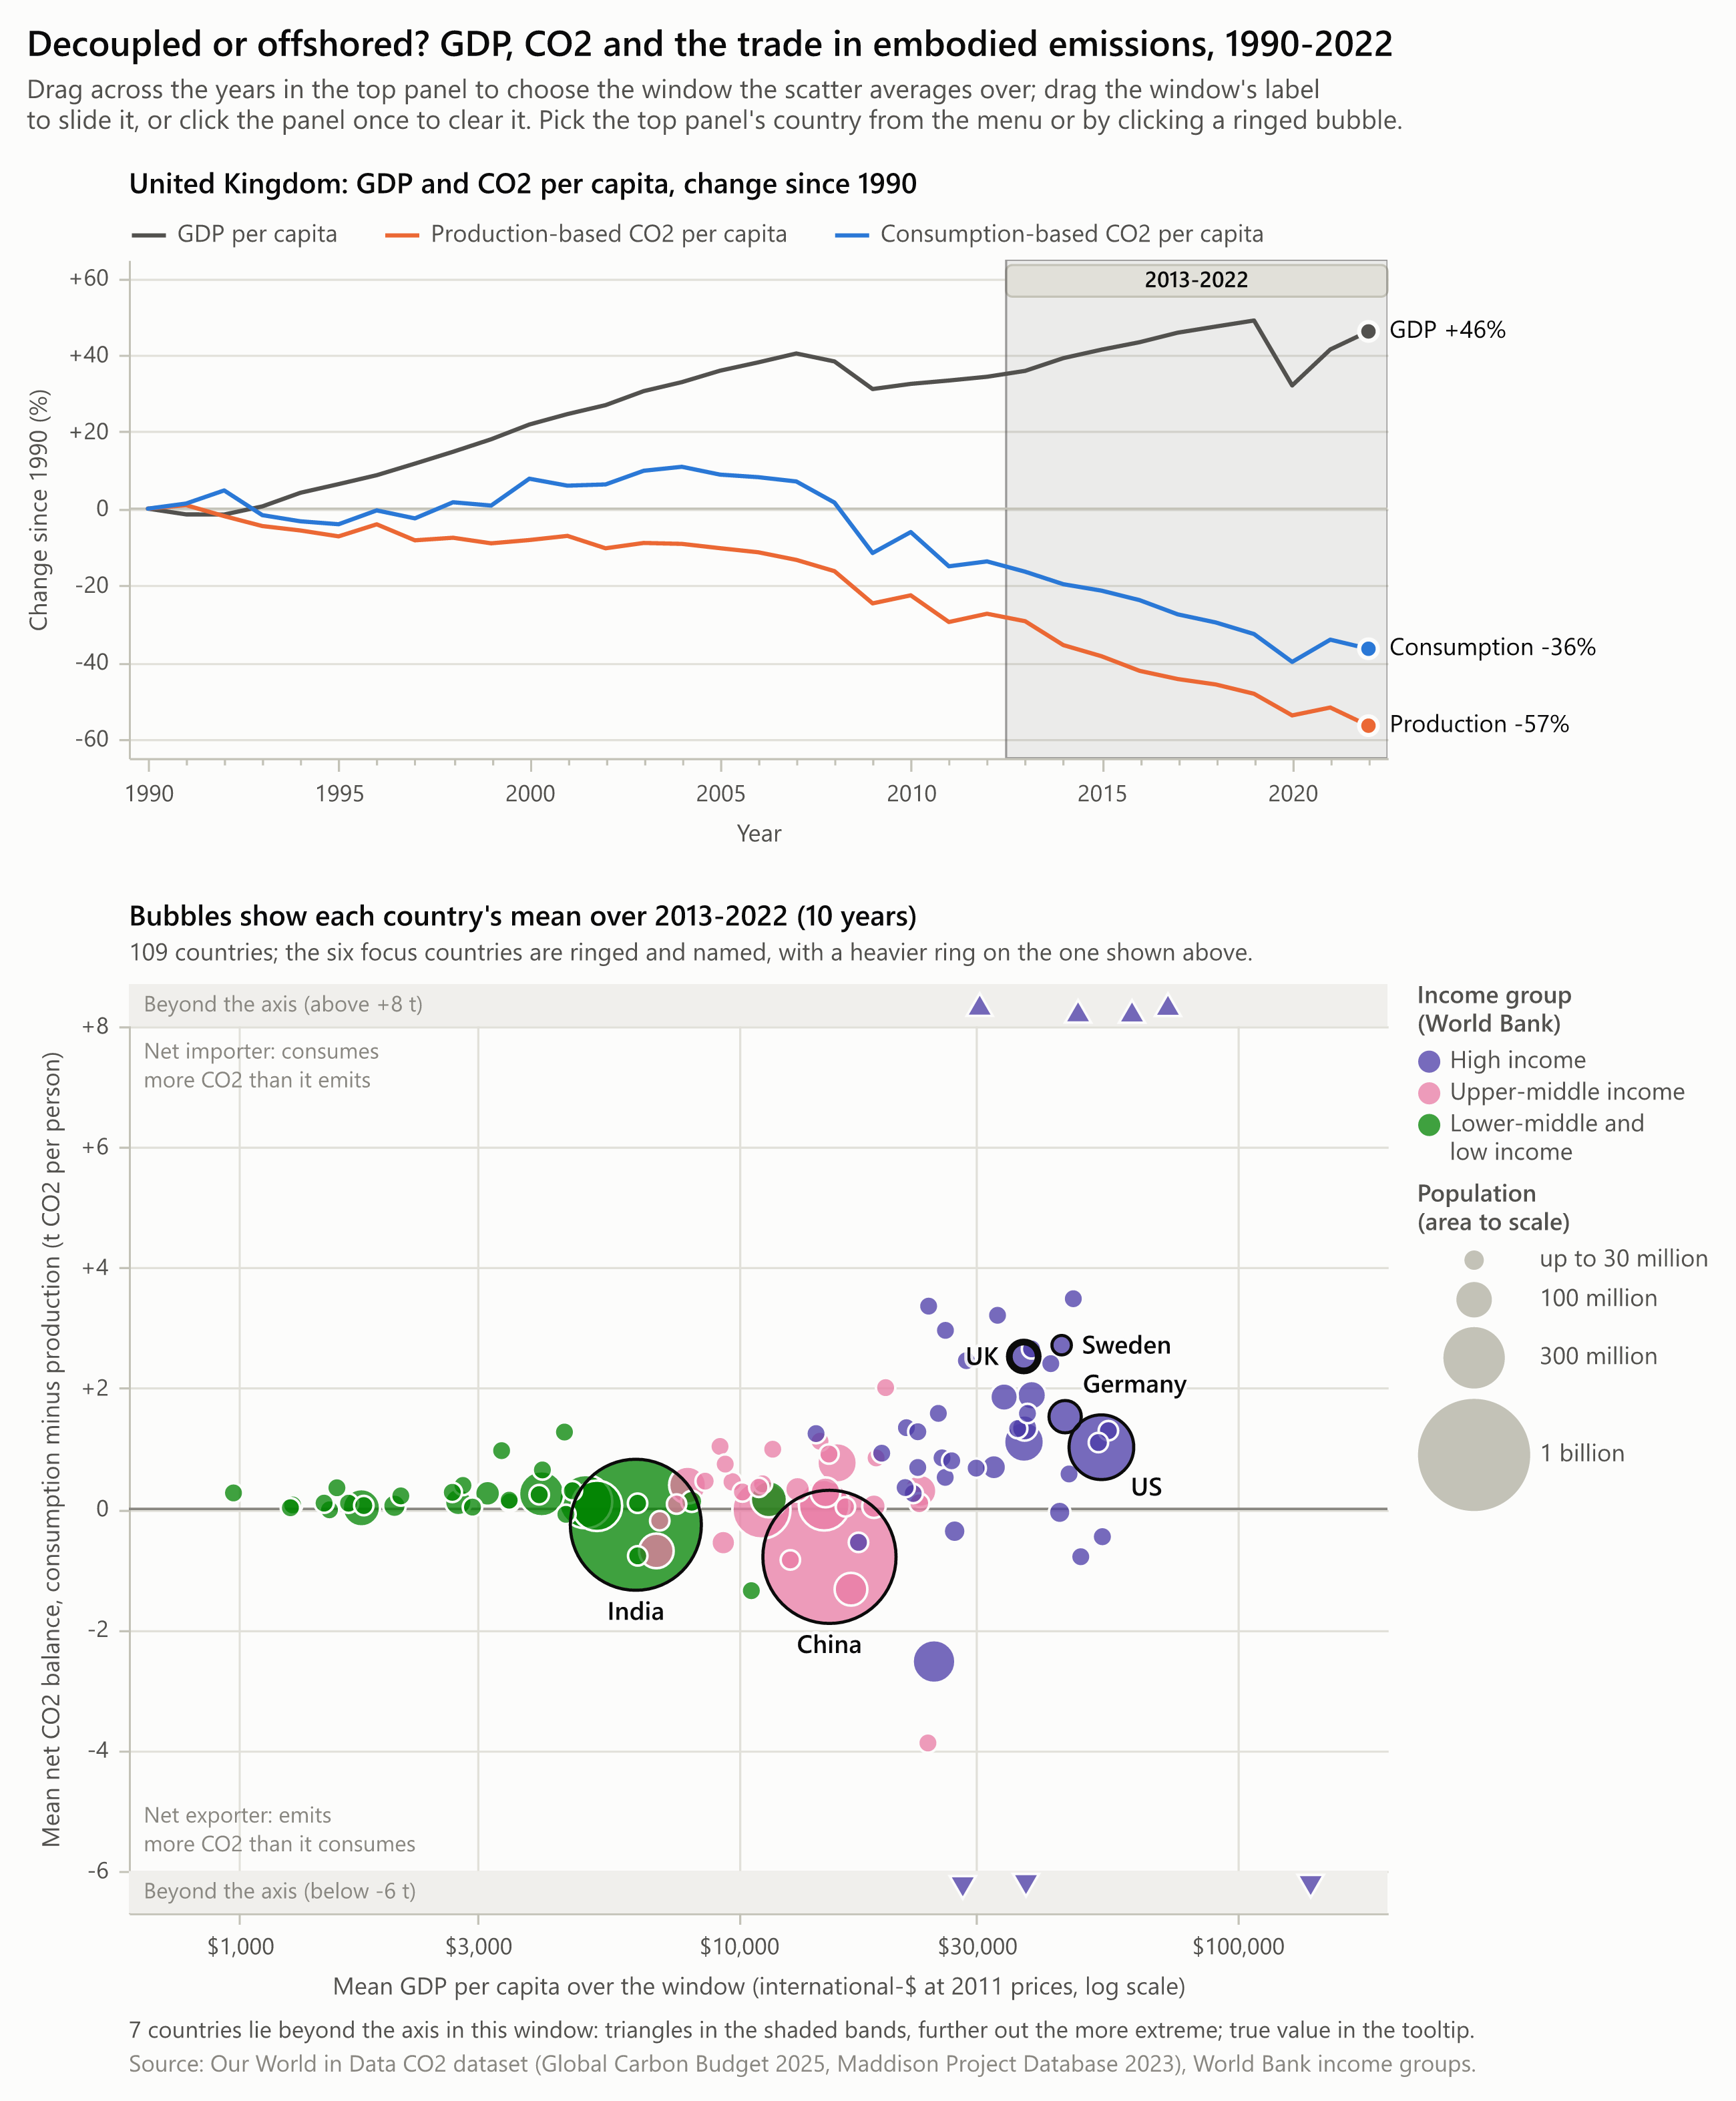

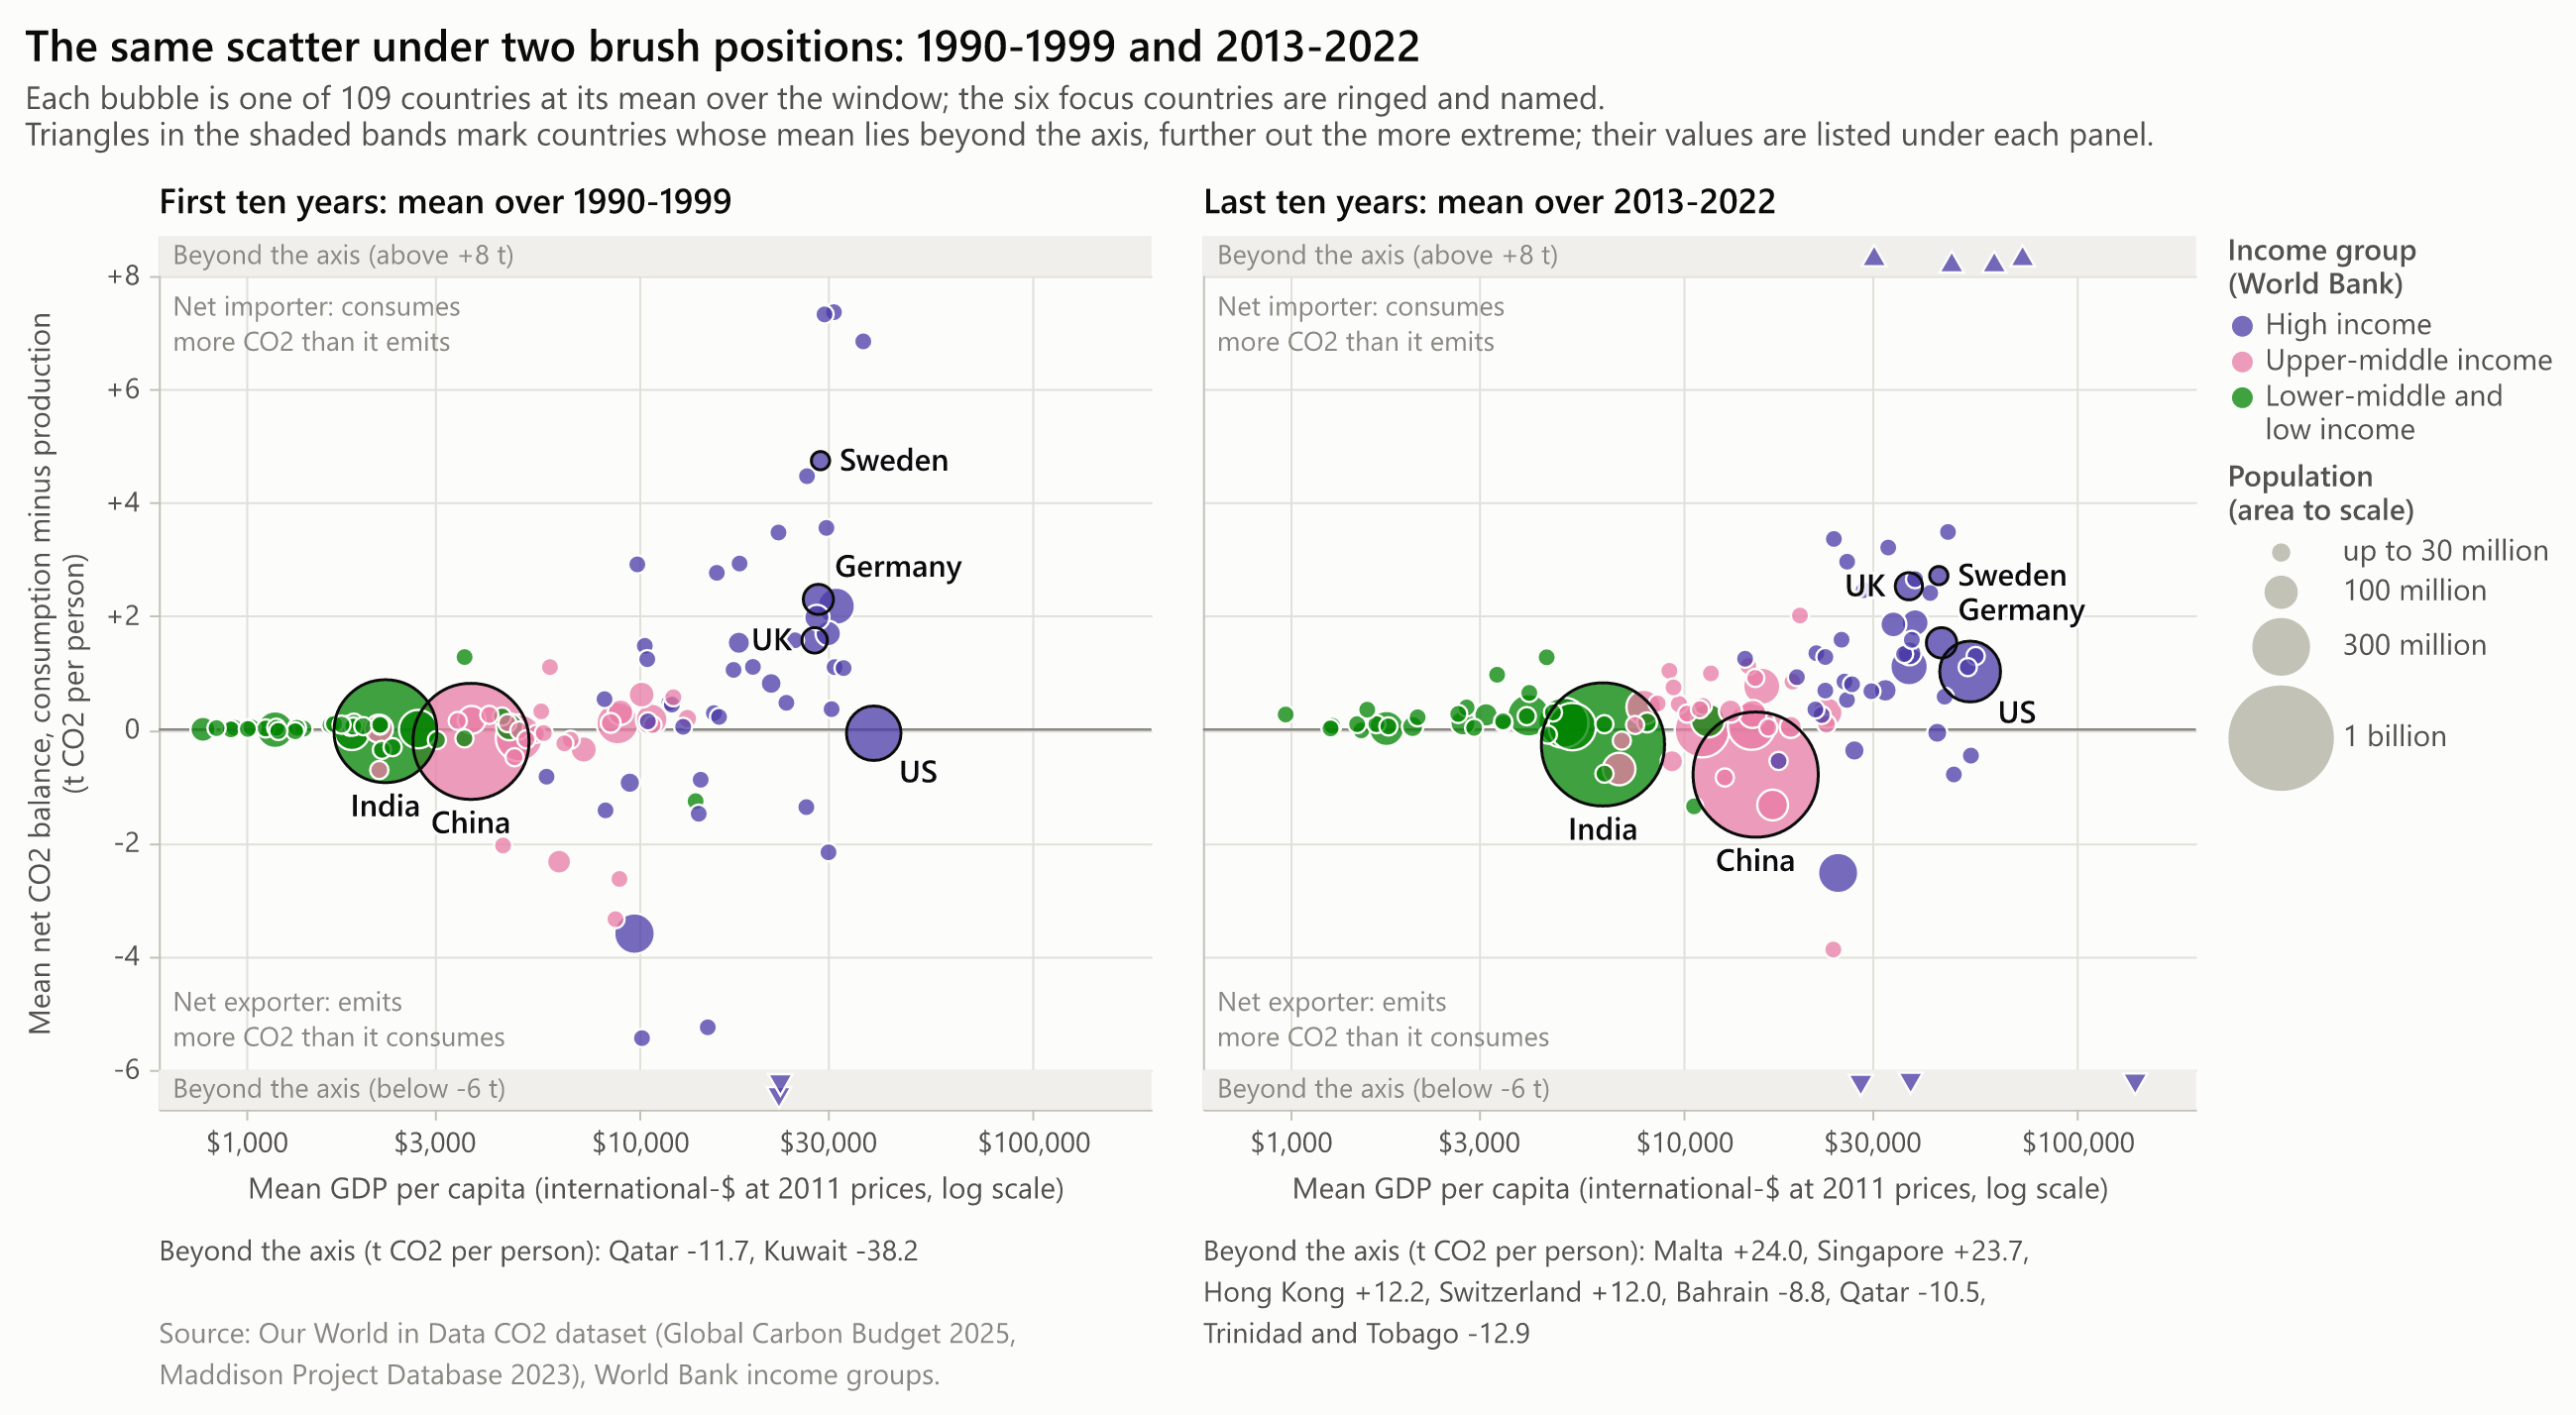

In [6]:
display(Image(filename=os.path.join(common.SHOTS, "01_vis1_altair_linked.png"), width=820))
display(Image(filename=os.path.join(common.SHOTS, "01_vis1_brush_comparison.png"), width=980))

## 3. Visualization 2 - connected scatterplot in D3

Time is taken off the x-axis. Each country is one path through GDP per capita (x) and
consumption-based CO2 per capita (y), from 1990 to 2022, with chevrons marking the direction of
travel. A path that heads down and to the right is a country getting richer with a smaller
footprint.

**Try it:** move the year slider or press play; hover a point for the numbers; tick *Show
production-based path* to see the gap between what a country emits and what it consumes; switch
the x-axis between log and linear; click a legend entry to hide a country.

The chart below is the live page `../web/d3_embed.html`, folded into a single iframe so that it
runs inside the notebook with no server.

In [7]:
from embed_web import iframe
display(HTML(iframe("d3_embed.html", height=860, title="D3 connected scatterplot")))

Its capture at 2022, for viewers that do not run JavaScript.

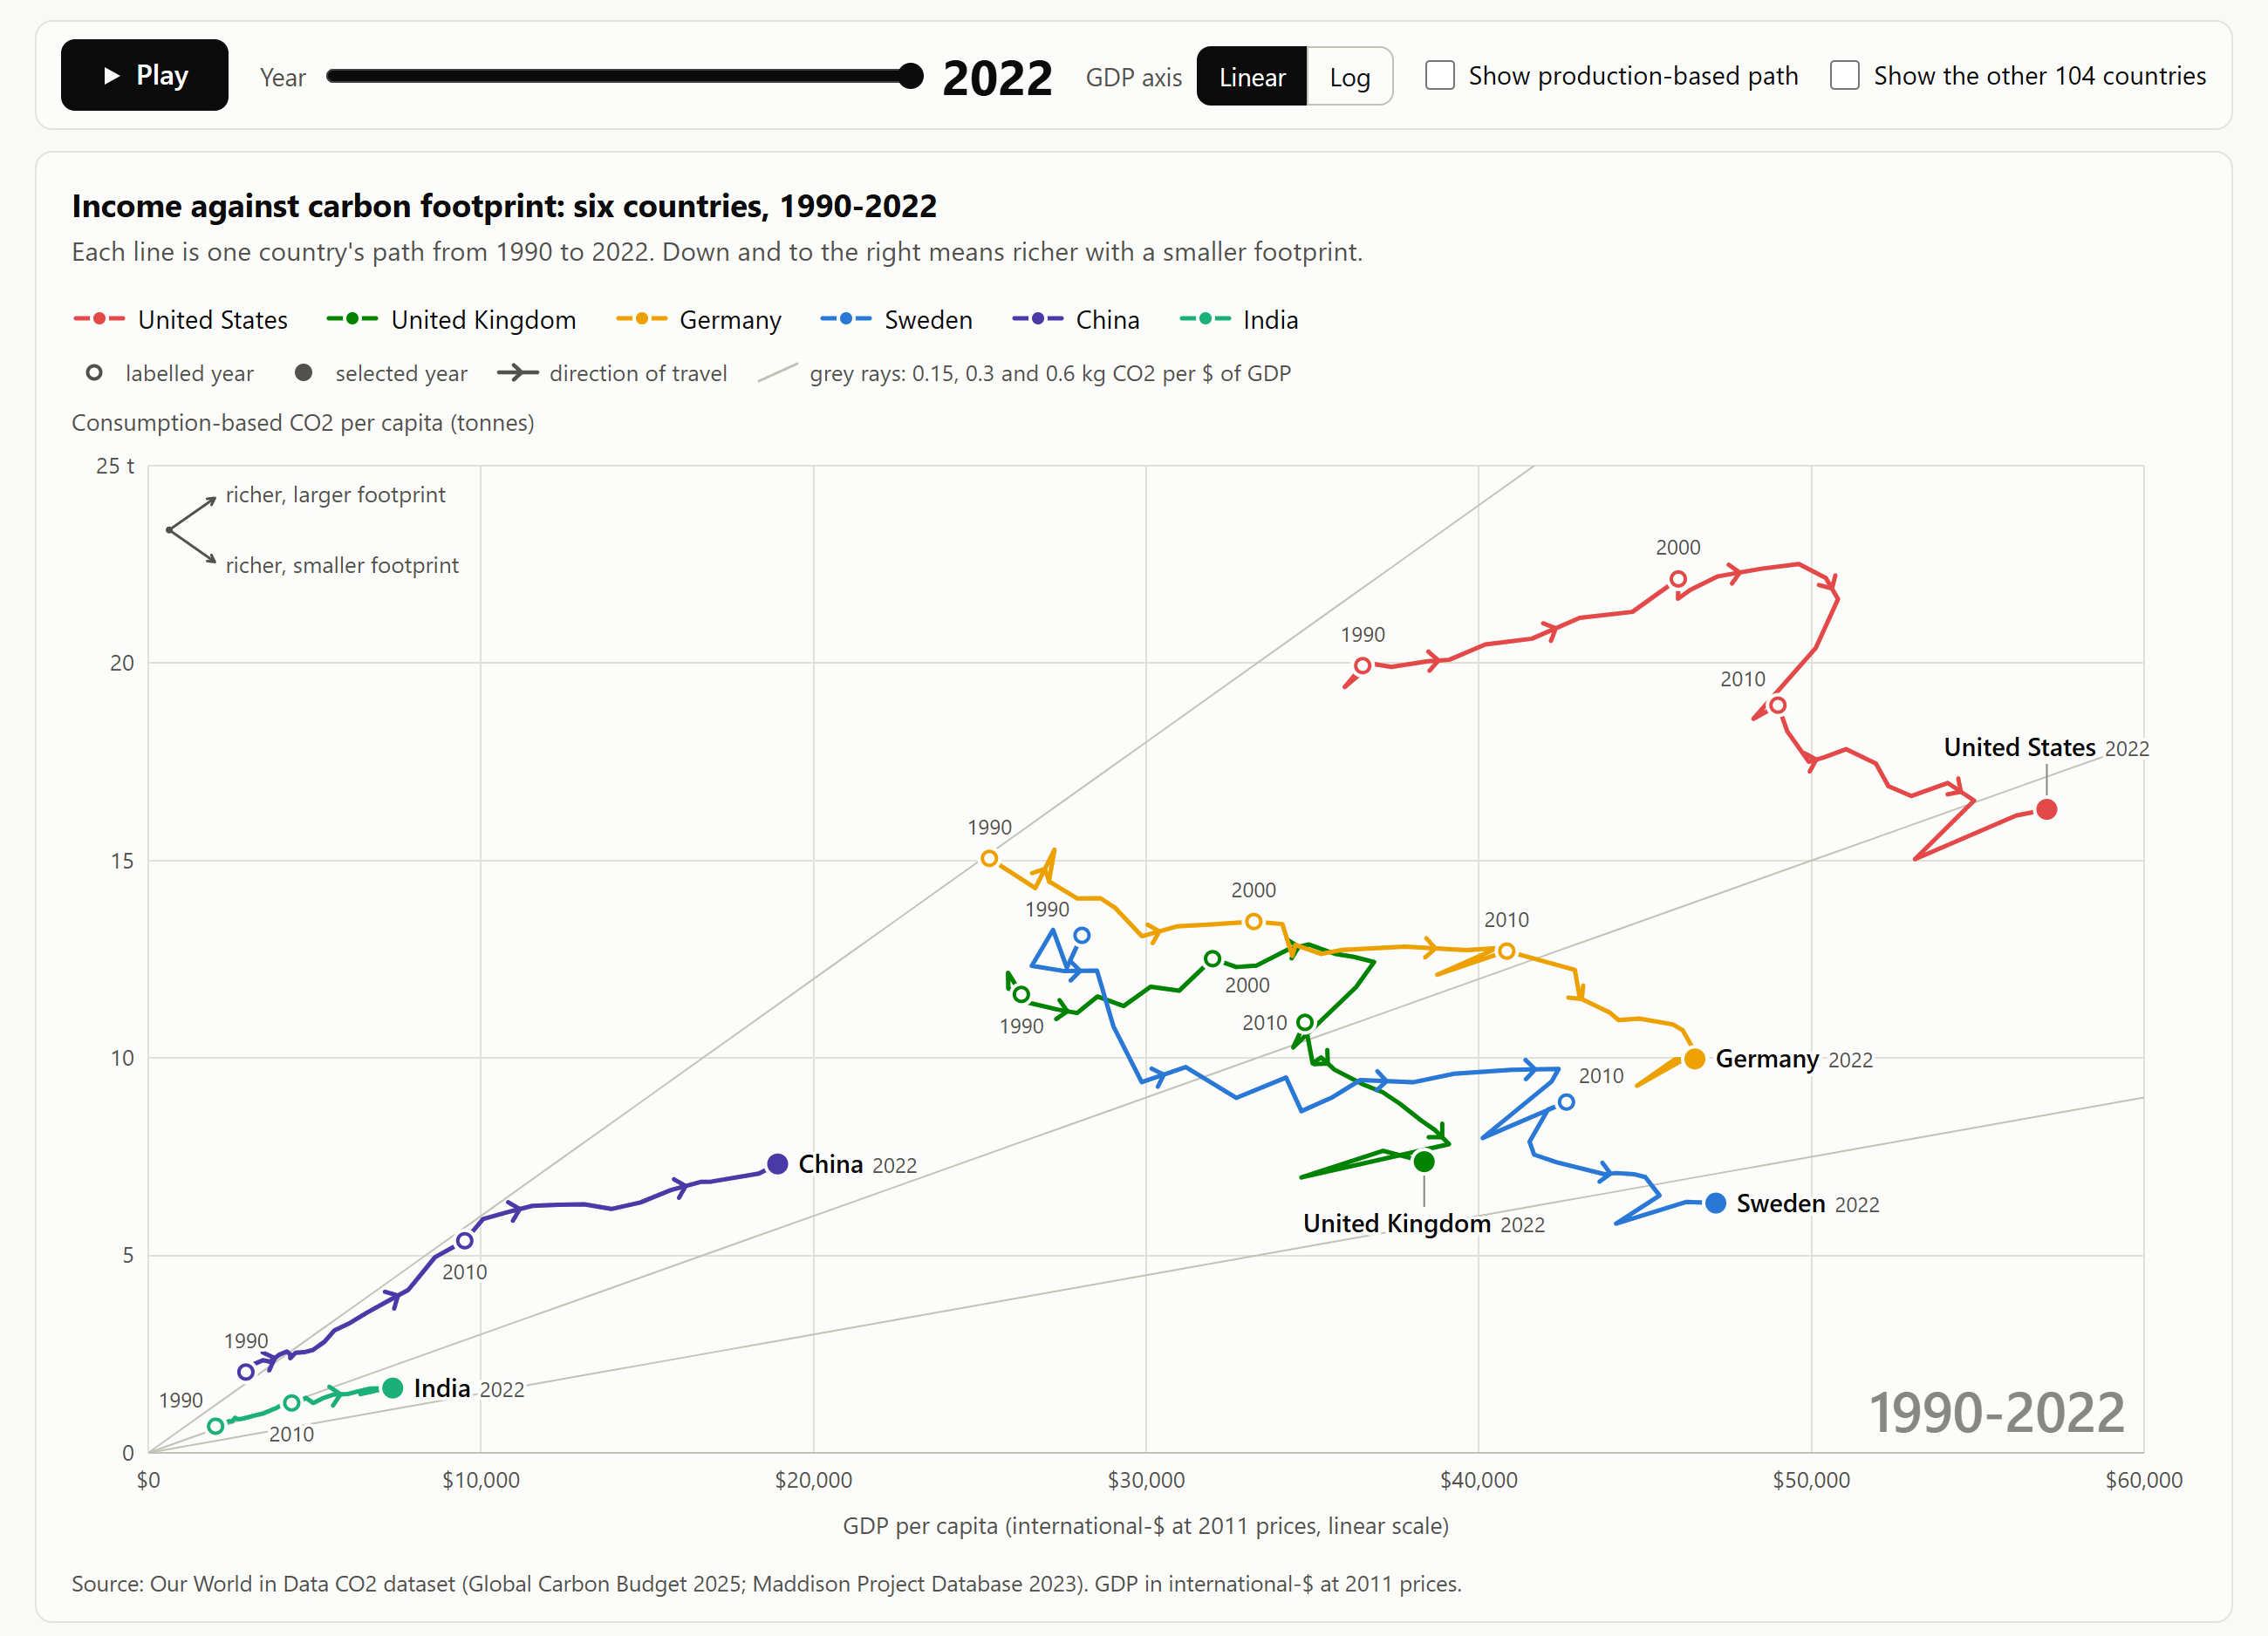

In [8]:
display(Image(filename=os.path.join(common.SHOTS, "02_vis2_d3_connected_scatter.png"),
              width=980))

## 4. Visualization 3 - diverging small multiples in Seaborn

The net balance itself, one facet per country on shared axes: blue where the country consumes
more CO2 than it emits (net importer), orange where it emits more than it consumes (net
exporter). Running the script draws the three figures, saves them and prints its checks.

In [9]:
import vis3_seaborn_diverging as v3
r3 = v3.main(show_results=False)

MODULE TWO - VISUALIZATION 3: DIVERGING SMALL MULTIPLES IN SEABORN
   seaborn 0.13.2, matplotlib 3.11.2, font Segoe UI
   figures 13 in wide at 200 dpi = 2600 px, for a 6.5 in slot in the report

1. Data
-------
   inputs\decoupling_focus.csv: 198 rows, 6 countries, 1990-2022
   check: 6 focus countries x 33 years, nothing missing in the plotted columns ... PASS
   check: net balance = consumption - production per person (worst gap 8.3e-09 t) ... PASS



2. Main figure: net balance per person, six facets
--------------------------------------------------
   screenshots\03_vis3_seaborn_diverging.png   2600 x 1980 px, 328 KB
   as printed: 8 lines 2 px, 17 points 8 px + 2 px ring, gridlines 1 px, baselines 1.5 px,
               wash opacity 0.42
   text: 60 pieces, set in #0b0b0b, #52514e, #898781
   check: main figure: the PNG is 2600 px wide, on the surface colour #fcfcfb ... PASS
   check: main figure: title, subtitle, legend of 2 entries and source note are there ... PASS
   check: main figure: every stroke is solid and every mark has its specified size ... PASS
   check: main figure: no text overlaps other text, sits on a mark or leaves the canvas ... PASS
   check: main figure: all text is plain ASCII and in ink, none in a data colour ... PASS
   check: main figure: none of the 27 barred words or phrases appears ... PASS
   check: subtitle: says how to read the sign and names both colours ... PASS
   check: legend: two entries, b


3. Derivation plate: United Kingdom
-----------------------------------
   screenshots\03a_vis3_derivation_plate.png   2600 x 1320 px, 262 KB
   as printed: 3 lines 2 px, 7 points 8 px + 2 px ring, gridlines 1 px, baselines 1.5 px,
               wash opacity 0.42
   text: 39 pieces, set in #0b0b0b, #52514e, #898781
   check: plate: the PNG is 2600 px wide, on the surface colour #fcfcfb ... PASS
   check: plate: title, subtitle, legend of 3 entries and source note are there ... PASS
   check: plate: every stroke is solid and every mark has its specified size ... PASS
   check: plate: no text overlaps other text, sits on a mark or leaves the canvas ... PASS
   check: plate: all text is plain ASCII and in ink, none in a data colour ... PASS
   check: plate: none of the 27 barred words or phrases appears ... PASS
   check: left panel: each line holds the 33 values of its account in the file ... PASS
   check: left panel: the consumption line is blue and the production line orange ... PAS


4. Absolute balance: Mt CO2 in 1990, 2007, 2022
-----------------------------------------------
   screenshots\03b_vis3_absolute_balance.png   2600 x 1240 px, 204 KB
   as printed: gridlines 1 px, baselines 1.5 px
   text: 35 pieces, set in #0b0b0b, #52514e, #898781
   check: bars: the PNG is 2600 px wide, on the surface colour #fcfcfb ... PASS
   check: bars: title, subtitle, legend of 2 entries and source note are there ... PASS
   check: bars: every stroke is solid and every mark has its specified size ... PASS
   check: bars: no text overlaps other text, sits on a mark or leaves the canvas ... PASS
   check: bars: all text is plain ASCII and in ink, none in a data colour ... PASS
   check: bars: none of the 27 barred words or phrases appears ... PASS
   Mt CO2                 1990      2007      2022
   United States           -80      +405      +511
   United Kingdom          +64      +205      +192
   Germany                +145      +189      +171
   Sweden                  +55

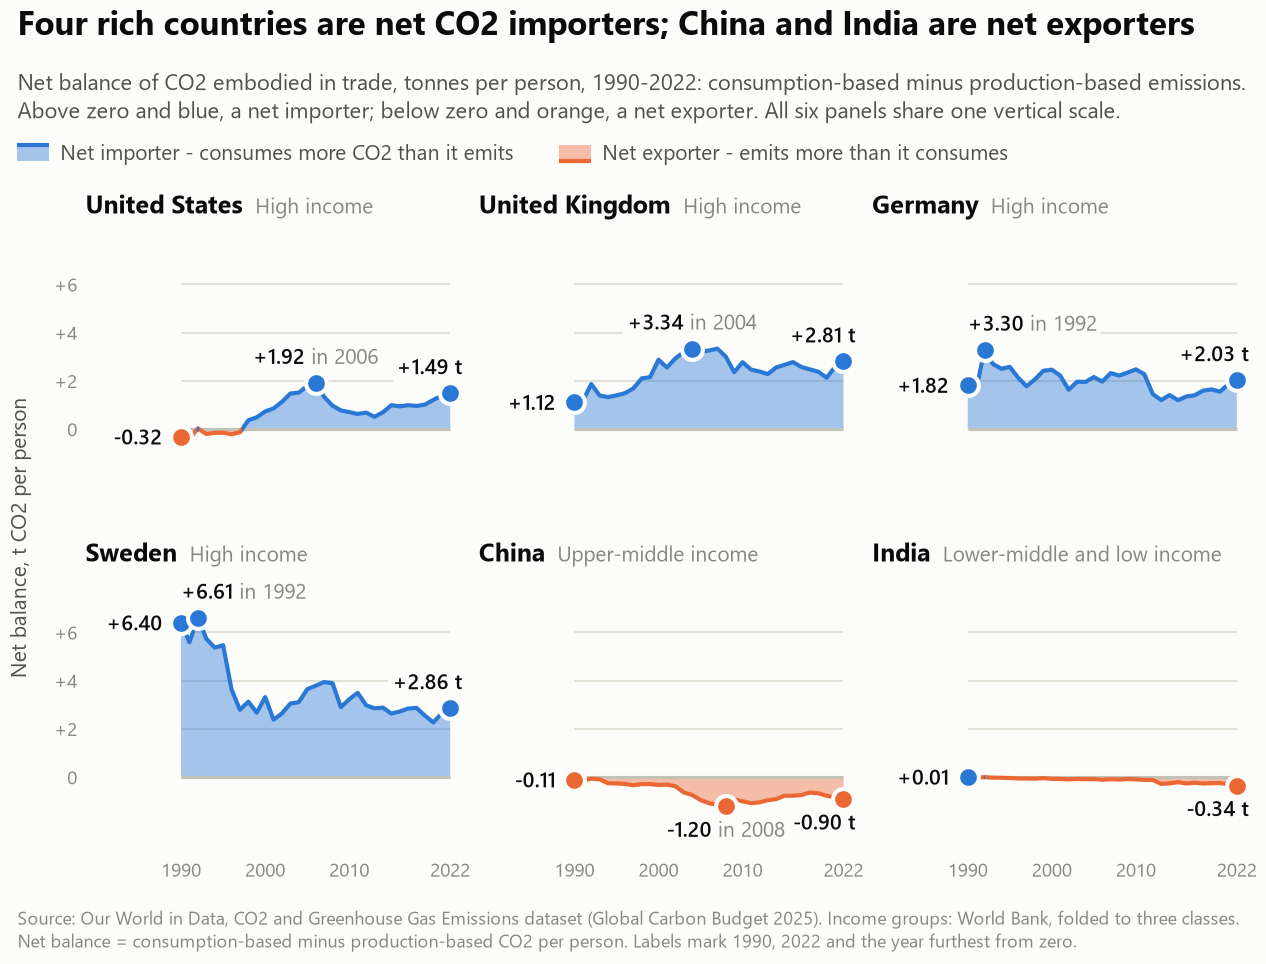

In [10]:
fig = v3.main_figure()
plt.show()

How the main figure is derived, for the United Kingdom: the two accounts as lines, then
the gap between them on its own.

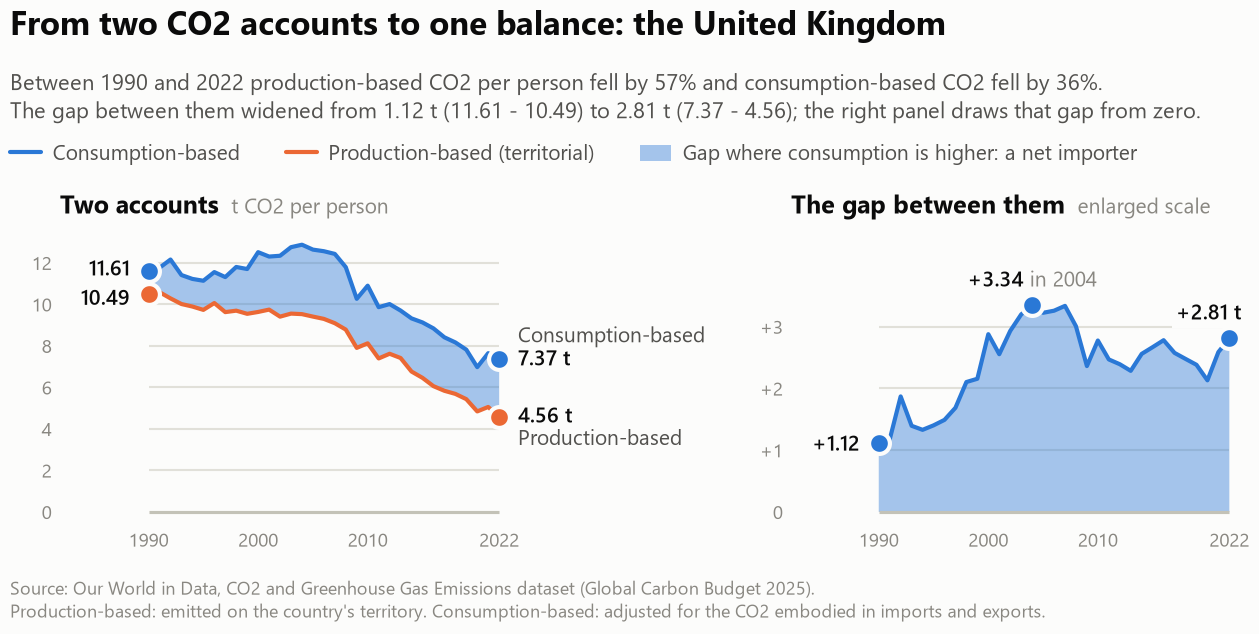

In [11]:
fig = v3.derivation_plate()
plt.show()

The same balance in absolute terms. Per person, China's export balance looks small; in
tonnes it is the largest flow of the six.

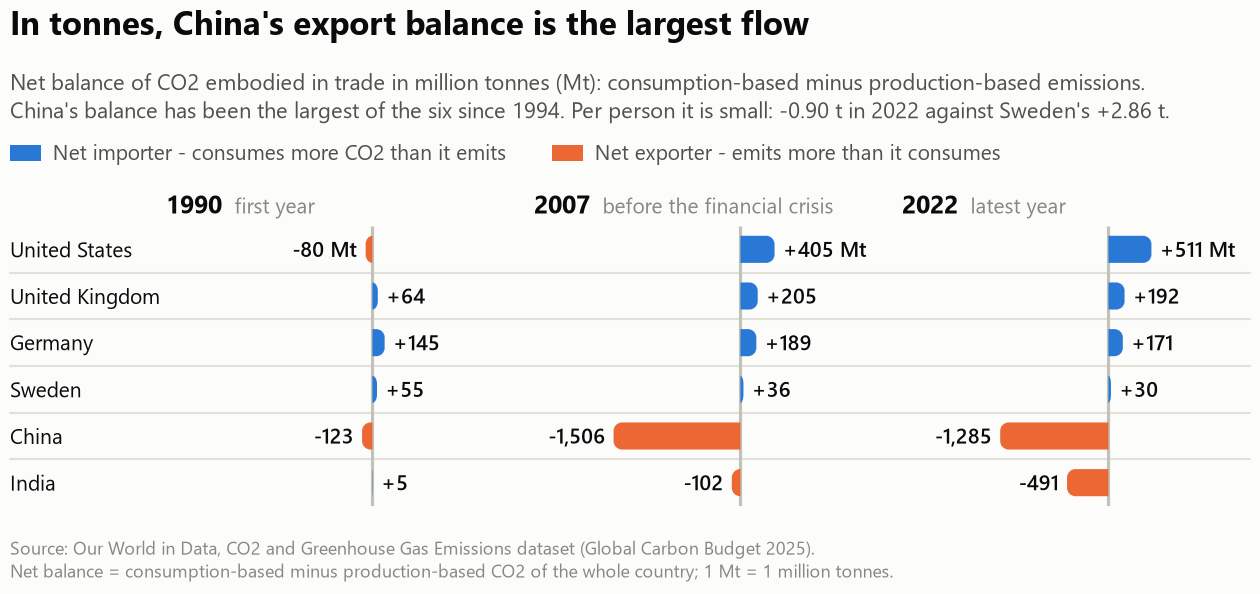

In [12]:
fig = v3.absolute_figure()
plt.show()

## 5. What the three views say together

How much of each importer's territorial cut was offset by a larger import balance? The offset
share is the change in the net balance divided by the fall in production-based CO2 per person,
1990 to 2022.

In [13]:
rows = []
for country in common.FOCUS[:4]:
    s = summary.loc[country]
    prod_cut = s["prod_pc_1990"] - s["prod_pc_2022"]
    cons_cut = s["cons_pc_1990"] - s["cons_pc_2022"]
    balance = s["net_pc_2022"] - s["net_pc_1990"]
    rows.append({"country": country, "GDP per person %": s["gdp_pc_change_pct"],
                 "territorial cut, t": prod_cut, "consumption cut, t": cons_cut,
                 "change in net balance, t": balance, "offset share %": 100 * balance / prod_cut})
display(pd.DataFrame(rows).set_index("country"))

,GDP per person %,"territorial cut, t","consumption cut, t","change in net balance, t",offset share %
country,,,,,
United States,56.33,5.45,3.64,1.81,33.24
United Kingdom,46.15,5.93,4.24,1.69,28.57
Germany,83.87,5.29,5.08,0.21,3.99
Sweden,67.89,3.24,6.78,-3.54,-109.06


Emissions fell on both accounts in all four countries while GDP per person rose, so the
decoupling is real. The import balance still matters. It widened until the mid-2000s, it gave back
33% of the territorial cut in the United States and 29% in the United Kingdom, and in 2022 the
United Kingdom consumed 62% more CO2 than it emitted at home. Germany's balance barely moved and
Sweden's shrank. China and India moved the other way on both axes and became the exporters.